# DARL: DDQN frente a PPO. Análisis final por método y por semilla

**Pregunta.** En el problema de mantenimiento del pipeline (A1 conservar, A2 reajustar el
transformador, A3 reentrenar XGBoost, A4 ambas), ¿conviene usar DDQN o PPO como agente?

**Qué se compara.**

1. **Por método** (semilla 42): DDQN v5 frente a tres versiones de PPO (v1, v2 y v3).
2. **Por semilla** (de la 42 a la 49): DDQN v5 y PPO v3, la mejor versión de PPO, con 8
   semillas cada uno.
3. **Análisis de grupo**: los dos agentes comparados con las 8 semillas juntas.

**Resumen de resultados.**

| | DDQN v5 | PPO v3 |
|---|---|---|
| Retorno medio en B-test (8 semillas) | 16,26 | 17,16 |
| Variación entre semillas (desviación típica) | alta (1,40) | baja (0,74) |
| ¿Diferencia significativa? | no (p = 0,27) | |
| Cuando falla... | reentrena aunque no haga falta | no descubre A2, pero no daña el modelo |

Todos los números y gráficos de este cuaderno se calculan a partir de los CSV de cada
ejecución en Kaggle. Los gráficos se guardan también como PNG en la carpeta `figuras/`.

## 1. Diseño del experimento

- **Mismo entorno en todas las ejecuciones.** Datos de PhysioNet, 200 camas durante 30
  días, deriva en cuatro escenarios (stable, covariate, concept y combined) y 27
  decisiones por episodio. La recompensa diaria es el AUC menos 0,05 por el costo de la
  acción. Solo cambia el agente.
- **Selección justa.** El checkpoint se elige en B-validation; B-test se evalúa una sola
  vez con los pesos congelados.
- **Semillas del agente.** La semilla 42 fija los pacientes, el XGBoost, los replays y
  B-test en todas las ejecuciones. Las semillas 43 a 49 cambian solo el azar del agente:
  pesos iniciales, exploración, minilotes y escenarios sorteados durante el entrenamiento.
  Así, todas las ejecuciones hacen el mismo examen.
- **Costo fijo común.** El costo real depende del tiempo medido en cada máquina. Para
  comparar, el retorno de B-test se recalcula con el costo medio de cada acción en v5.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, ScalarFormatter
from scipy.stats import mannwhitneyu

ROOT = next(p for p in Path.cwd().resolve().parents if (p / 'pyproject.toml').is_file())
K = ROOT / 'kaggle'
FIG = K / 'ppo-dummy/analisis/figuras'
FIG.mkdir(exist_ok=True)
ACTIONS = ['A1', 'A2', 'A3', 'A4']
SCENARIOS = ['stable', 'concept', 'covariate', 'combined']
METHODS = ['DDQN v5', 'PPO v1', 'PPO v2', 'PPO v3']
pd.set_option('display.float_format', lambda x: f'{x:.2f}'.replace('.', ','))

INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
COLOR = {'DDQN v5': '#2a78d6', 'PPO v3': '#eb6834', 'PPO v1': '#1baf7a', 'PPO v2': '#eda100'}
ACTION_COLOR = dict(zip(ACTIONS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'axes.grid.axis': 'y',
                     'grid.color': GRID, 'axes.titlecolor': INK, 'axes.titlelocation': 'left'})


def save(fig, name):
    """Usa coma decimal en los ejes, guarda el gráfico en figuras/ y lo muestra."""
    comma = FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(comma)
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()


RUNS = [('DDQN v5', 42, 'dqn-dummy/v5/outputs', 'dqn'),
        ('PPO v1', 42, 'ppo-dummy/v1/outputs', 'ppo'),
        ('PPO v2', 42, 'ppo-dummy/v2/outputs', 'ppo'),
        ('PPO v3', 42, 'ppo-dummy/v3/outputs', 'ppo')]
RUNS += [(agent, seed, f'ppo-dummy/seeds/{folder}-s{seed}/outputs', policy)
         for agent, folder, policy in [('DDQN v5', 'ddqn', 'dqn'), ('PPO v3', 'ppo', 'ppo')]
         for seed in range(43, 50)]

v5_actions = pd.read_csv(K / 'dqn-dummy/v5/outputs/actions.csv')
FIXED_COST = (v5_actions[v5_actions.policy.isin(ACTIONS)].groupby('executed').cost.mean()
              .reindex(range(4)).fillna(0).to_numpy())


def fixed_return(days):
    """Retorno de un episodio de B-test con el costo fijo común de v5."""
    return (days.auc.fillna(0) - FIXED_COST[days.executed]).sum()


BEST_FIXED = {s: max(fixed_return(g[g.policy.eq(a)]) for a in ACTIONS)
              for s, g in v5_actions.groupby('scenario')}
pd.Series(BEST_FIXED, name='mejor acción fija (retorno)').loc[SCENARIOS].to_frame()

,mejor acción fija (retorno)
stable,"17,93"
concept,"17,72"
covariate,"17,77"
combined,"17,64"


La tabla anterior es la **referencia**: el retorno de la mejor acción fija en cada
escenario (A1 en stable y concept, A2 en covariate y combined). Un agente bueno debería
quedar cerca de esos valores.

## 2. Control: el entorno es idéntico en las 18 ejecuciones

Las políticas fijas (A1 a A4, aleatoria y heurística) se evalúan en cada ejecución. Si el
entorno no ha cambiado, deben dar exactamente el mismo AUC y las mismas acciones que en
DDQN v5.

In [2]:
v5_daily = pd.read_csv(K / 'dqn-dummy/v5/outputs/daily_metrics.csv')
rows, checks = [], []
for agent, seed, path, policy in RUNS:
    out = K / path
    daily = pd.read_csv(out / 'daily_metrics.csv')
    m = v5_daily.merge(daily, on=['scenario', 'policy', 'day'], suffixes=('_v5', ''))
    fixed = m[m.policy.isin(ACTIONS + ['random', 'heuristic'])]
    integrity = pd.read_csv(out / 'integrity_checks.csv')
    selection = pd.read_csv(out / 'checkpoint_selection.csv').iloc[-1]
    checks.append(dict(agente=agent, semilla=seed, filas=len(fixed),
                       max_dif_auc=np.nanmax(np.abs(fixed.auc_v5 - fixed.auc)),
                       acciones_iguales=(fixed.action_v5 == fixed.action).mean(),
                       controles_ok=f"{integrity.passed.sum()}/{len(integrity)}"))
    acts = pd.read_csv(out / 'actions.csv')
    for scenario, g in acts[acts.policy.eq(policy)].groupby('scenario'):
        ret = fixed_return(g)
        rows.append(dict(agente=agent, semilla=seed, escenario=scenario, retorno=ret,
                         brecha=BEST_FIXED[scenario] - ret, auc=g.auc.mean(),
                         **{a: int((g.executed == i).sum()) for i, a in enumerate(ACTIONS)},
                         episodio_elegido=int(selection.selected_episode),
                         acuerdo=selection.selected_window_agreement))
results = pd.DataFrame(rows)
results['escenario'] = pd.Categorical(results.escenario, SCENARIOS)
pd.DataFrame(checks)

,agente,semilla,filas,max_dif_auc,acciones_iguales,controles_ok
0,DDQN v5,42,720,"0,00","1,00",33/33
1,PPO v1,42,720,"0,00","1,00",33/33
2,PPO v2,42,720,"0,00","1,00",33/33
3,PPO v3,42,720,"0,00","1,00",33/33
4,DDQN v5,43,720,"0,00","1,00",33/33
5,DDQN v5,44,720,"0,00","1,00",33/33
6,DDQN v5,45,720,"0,00","1,00",33/33
7,DDQN v5,46,720,"0,00","1,00",33/33
8,DDQN v5,47,720,"0,00","1,00",33/33
9,DDQN v5,48,720,"0,00","1,00",33/33


En todas las ejecuciones la diferencia de AUC es 0, las acciones coinciden al 100 % y
todos los controles de integridad se superan. **Cualquier diferencia de resultados se
debe al agente.**

## 3. Por método: DDQN v5 frente a PPO v1, v2 y v3 (semilla 42)

| Versión | Qué se cambió | Por qué |
|---|---|---|
| PPO v1 | PPO básico: actualiza cada 4 episodios, lambda de GAE = 0,5 | primera versión, mismo presupuesto que DDQN |
| PPO v2 | configuración estándar de PPO: 20 episodios por actualización, 10 épocas, lambda = 0,95 | v1 casi no cambiaba la política (recorte de como mucho el 1 %) |
| PPO v3 | v2 más una política inicial prudente (90 % de A1) | en v2 ningún episodio de entrenamiento terminó sin reentrenar |

Acciones = días con A1/A2/A3/A4 en B-test (27 decisiones por escenario).

In [3]:
def action_text(df):
    return df[ACTIONS].astype(str).agg('/'.join, axis=1)


by_method = results[results.semilla.eq(42)].copy()
by_method['acciones'] = action_text(by_method)
table = by_method.pivot(index='escenario', columns='agente', values='retorno')[METHODS]
table.loc['media'] = table.mean()
display(table.round(2))
by_method.pivot(index='escenario', columns='agente', values='acciones')[METHODS]

agente,DDQN v5,PPO v1,PPO v2,PPO v3
escenario,,,,
stable,"17,93","17,93","14,87","17,93"
concept,"17,72","17,72","14,84","17,72"
covariate,"17,89","15,16","14,22","14,38"
combined,"17,76","15,65","14,23","14,47"
media,"17,83","16,62","14,54","16,13"


agente,DDQN v5,PPO v1,PPO v2,PPO v3
escenario,,,,
stable,27/0/0/0,27/0/0/0,0/10/3/14,27/0/0/0
concept,27/0/0/0,27/0/0/0,1/8/4/14,27/0/0/0
covariate,5/22/0/0,9/0/8/10,0/4/4/19,19/0/8/0
combined,5/22/0/0,9/0/11/7,0/4/4/19,19/0/8/0


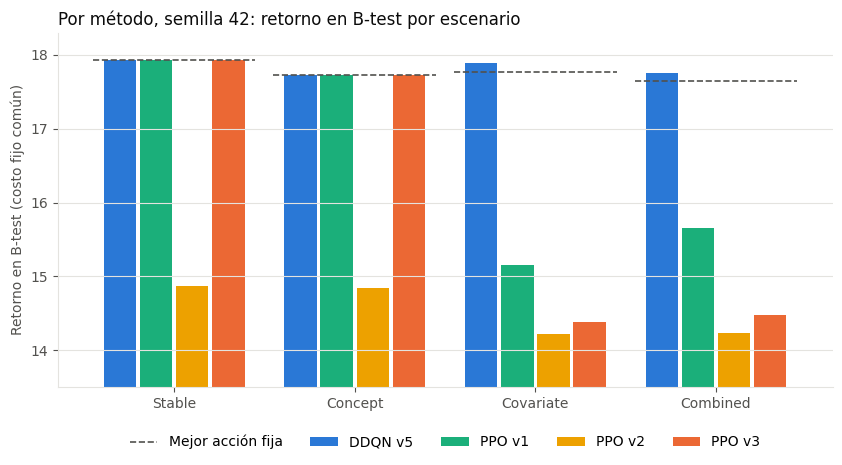

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.6))
width = .2
for j, method in enumerate(METHODS):
    x = np.arange(len(SCENARIOS)) + (j - 1.5) * width
    ax.bar(x, table.loc[SCENARIOS, method], width * .9, color=COLOR[method], label=method)
for i, scenario in enumerate(SCENARIOS):
    ax.hlines(BEST_FIXED[scenario], i - .45, i + .45, color=MUTED, ls='--', lw=1.2,
              label='Mejor acción fija' if i == 0 else None)
ax.set_xticks(range(len(SCENARIOS)), [s.capitalize() for s in SCENARIOS])
ax.set(ylim=(13.5, 18.3), ylabel='Retorno en B-test (costo fijo común)')
ax.set_title('Por método, semilla 42: retorno en B-test por escenario')
ax.legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(.5, -.1))
save(fig, '01_por_metodo')

**Lectura por método (solo semilla 42).**

- **DDQN v5** iguala a la mejor acción fija en los cuatro escenarios: A1 en stable y
  concept, A2 en covariate y combined.
- **PPO v1** acierta en stable y concept, pero en covariate y combined reentrena y nunca
  usa A2.
- **PPO v2** empeora en todo: aprende a reentrenar casi siempre. Al reentrenar, el
  pipeline se degrada sin vuelta atrás, y PPO solo aprende de su propia política, así que
  nunca llegó a observar qué pasa si no reentrena.
- **PPO v3** corrige eso en stable y concept, pero con esta semilla tampoco descubre A2.

Con una sola semilla parecía que DDQN era claramente mejor. La sección 4 muestra que esa
conclusión dependía de la semilla.

## 4. Por semilla: DDQN v5 y PPO v3 (semillas 42 a 49)

Retorno medio de los cuatro escenarios en cada semilla. **Brecha máxima** = cuánto queda
el agente por debajo de la mejor acción fija en su peor escenario. Se marca **falla**
cuando esa brecha supera 1,0.

In [5]:
seeds = results[results.agente.isin(['DDQN v5', 'PPO v3'])]
per_seed = (seeds.groupby(['agente', 'semilla'])
            .agg(retorno=('retorno', 'mean'), brecha_max=('brecha', 'max'),
                 acuerdo=('acuerdo', 'first'), episodio=('episodio_elegido', 'first'))
            .reset_index())
per_seed['falla'] = np.where(per_seed.brecha_max > 1.0, 'sí', 'no')
per_seed.pivot(index='semilla', columns='agente', values=['retorno', 'brecha_max', 'falla', 'acuerdo'])

retorno        brecha_max          falla        acuerdo       
agente  DDQN v5 PPO v3    DDQN v5 PPO v3 DDQN v5 PPO v3 DDQN v5 PPO v3
semilla                                                               
42        17,83  16,13       0,00   3,39      no     sí    0,69   1,00
43        17,70  17,78       0,15   0,00      no     no    0,07   0,96
44        15,27  17,66       3,66   0,24      sí     no    0,13   1,00
45        14,62  17,31       3,34   1,93      sí     sí    0,37   0,87
46        17,70  16,70       0,15   2,20      no     sí    0,00   1,00
47        15,23  17,78       2,84   0,00      sí     no    0,15   1,00
48        14,84  17,81       3,41   0,00      sí     no    0,10   1,00
49        16,86  16,11       1,25   3,38      sí     sí    0,43   0,96

### 4.1 Detalle por semilla y escenario (retorno y acciones A1/A2/A3/A4)

In [6]:
detail = seeds.copy()
detail['celda'] = detail.retorno.map(lambda v: f'{v:.2f}'.replace('.', ',')) + '  (' + action_text(detail) + ')'
detail.pivot(index=['agente', 'semilla'], columns='escenario', values='celda')

escenario                    stable             concept           covariate  \
agente  semilla                                                               
DDQN v5 42        17,93  (27/0/0/0)   17,72  (27/0/0/0)   17,89  (5/22/0/0)   
        43        17,79  (0/27/0/0)   17,61  (0/27/0/0)   17,77  (0/27/0/0)   
        44        16,44  (25/0/1/1)   16,11  (24/0/1/2)   14,55  (18/2/7/0)   
        45       14,85  (10/6/0/11)   14,75  (6/9/0/12)  14,43  (2/10/0/15)   
        46        17,79  (0/27/0/0)   17,61  (0/27/0/0)   17,77  (0/27/0/0)   
        47       15,36  (14/1/12/0)  15,53  (15/1/11/0)   14,94  (1/5/21/0)   
        48        15,29  (16/2/1/8)   15,20  (14/4/2/7)   14,63  (20/4/0/3)   
        49       16,68  (14/2/11/0)   17,26  (15/6/6/0)   16,58  (8/15/4/0)   
PPO v3  42        17,93  (27/0/0/0)   17,72  (27/0/0/0)   14,38  (19/0/8/0)   
        43        17,93  (27/0/0/0)   17,72  (27/0/0/0)  17,81  (10/17/0/0)   
        44        17,93  (27/0/0/0)   17,72  (27/0/0/0)   17,60  (22/5/0/0)   
        45        17,93  (27/0/0/0)   17,72  (27/0/0/0)  15,84  (17/10/0/0)   
        46        17,93  (27/0/0/0)   17,72  (27/0/0/0)   15,58  (23/0/0/4)   
        47        17,93  (27/0/0/0)   17,72  (27/0/0/0)   17,79  (8/19/0/0)   
        48        17,93  (27/0/0/0)   17,72  (27/0/0/0)   17,86  (4/23/0/0)   
        49        17,93  (27/0/0/0)   17,72  (27/0/0/0)   14,50  (24/0/0/3)   

escenario                  combined  
agente  semilla                      
DDQN v5 42        17,76  (5/22/0/0)  
        43        17,64  (0/27/0/0)  
        44        13,98  (21/2/4/0)  
        45       14,45  (2/10/1/14)  
        46        17,64  (0/27/0/0)  
        47        15,08  (2/5/20/0)  
        48        14,23  (22/2/0/3)  
        49        16,90  (7/17/3/0)  
PPO v3  42        14,47  (19/0/8/0)  
        43       17,66  (10/17/0/0)  
        44        17,40  (21/6/0/0)  
        45       17,72  (12/15/0/0)  
        46        15,57  (23/0/0/4)  
        47        17,68  (8/19/0/0)  
        48        17,72  (4/23/0/0)  
        49        14,27  (27/0/0/0)

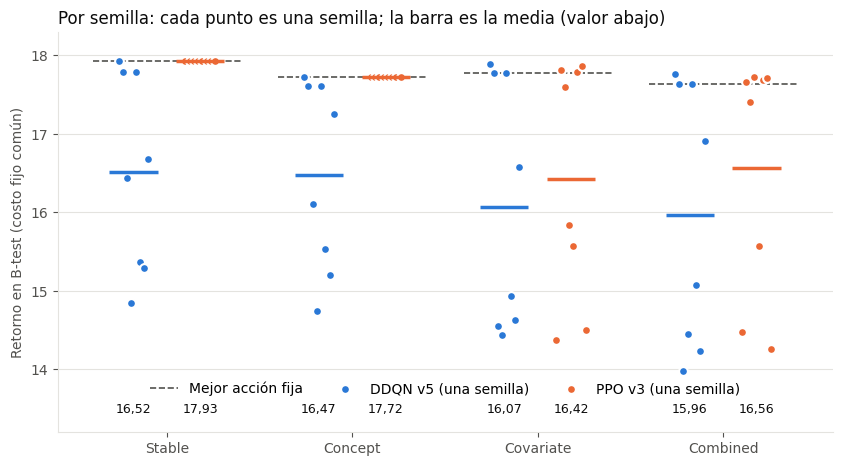

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.2))
for i, scenario in enumerate(SCENARIOS):
    ax.hlines(BEST_FIXED[scenario], i - .4, i + .4, color=MUTED, ls='--', lw=1.2,
              label='Mejor acción fija' if i == 0 else None)
    for j, agent in enumerate(['DDQN v5', 'PPO v3']):
        v = seeds[(seeds.escenario == scenario) & (seeds.agente == agent)].sort_values('semilla').retorno.to_numpy()
        center = i + (j - .5) * .36
        ax.scatter(center + np.linspace(-.08, .08, len(v)), v, s=40, color=COLOR[agent],
                   edgecolor='white', linewidth=1.5, zorder=3, label=f'{agent} (una semilla)' if i == 0 else None)
        ax.hlines(v.mean(), center - .13, center + .13, color=COLOR[agent], lw=2.5, zorder=4)
        ax.text(center, 13.45, f'{v.mean():.2f}'.replace('.', ','), ha='center', fontsize=9, color=INK)
ax.set_xticks(range(4), [s.capitalize() for s in SCENARIOS])
ax.set(ylim=(13.2, 18.3), ylabel='Retorno en B-test (costo fijo común)')
ax.set_title('Por semilla: cada punto es una semilla; la barra es la media (valor abajo)')
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(.5, .06), ncol=3)
save(fig, '02_por_semilla_y_escenario')

**Qué muestra el gráfico.**

- En **stable** y **concept**, PPO v3 elige A1 en las 8 semillas y queda siempre en la
  línea de la mejor acción fija. DDQN se dispersa mucho: en varias semillas reentrena sin
  que haga falta.
- En **covariate** y **combined** ambos fallan a veces. Las semillas buenas de los dos
  llegan a la mejor acción fija, que es A2.

## 5. Análisis de grupo: los dos agentes con las 8 semillas juntas

In [8]:
summary = per_seed.groupby('agente').agg(
    media=('retorno', 'mean'), desv_tipica=('retorno', 'std'), mediana=('retorno', 'median'),
    minimo=('retorno', 'min'), maximo=('retorno', 'max'),
    semillas_con_falla=('falla', lambda x: f"{(x == 'sí').sum()} de {len(x)}"),
    acuerdo_medio=('acuerdo', 'mean'))
display(summary.round(2))

ddqn = per_seed[per_seed.agente.eq('DDQN v5')].retorno.to_numpy()
ppo = per_seed[per_seed.agente.eq('PPO v3')].retorno.to_numpy()
rng = np.random.default_rng(0)
boot = [rng.choice(ppo, len(ppo)).mean() - rng.choice(ddqn, len(ddqn)).mean() for _ in range(10000)]
low, high = np.percentile(boot, [2.5, 97.5])
p_value = mannwhitneyu(ppo, ddqn).pvalue
num = lambda v: f'{v:.2f}'.replace('.', ',')
print(f'Diferencia de medias (PPO v3 menos DDQN v5): {num(ppo.mean() - ddqn.mean())}')
print(f'Intervalo de confianza al 95 % (bootstrap): [{num(low)}; {num(high)}]')
print(f'Prueba de Mann-Whitney: p = {num(p_value)}')

,media,desv_tipica,mediana,minimo,maximo,semillas_con_falla,acuerdo_medio
agente,,,,,,,
DDQN v5,"16,26","1,40","16,06","14,62","17,83",5 de 8,"0,24"
PPO v3,"17,16","0,74","17,48","16,11","17,81",4 de 8,"0,97"


Diferencia de medias (PPO v3 menos DDQN v5): 0,90
Intervalo de confianza al 95 % (bootstrap): [-0,12; 1,92]
Prueba de Mann-Whitney: p = 0,27


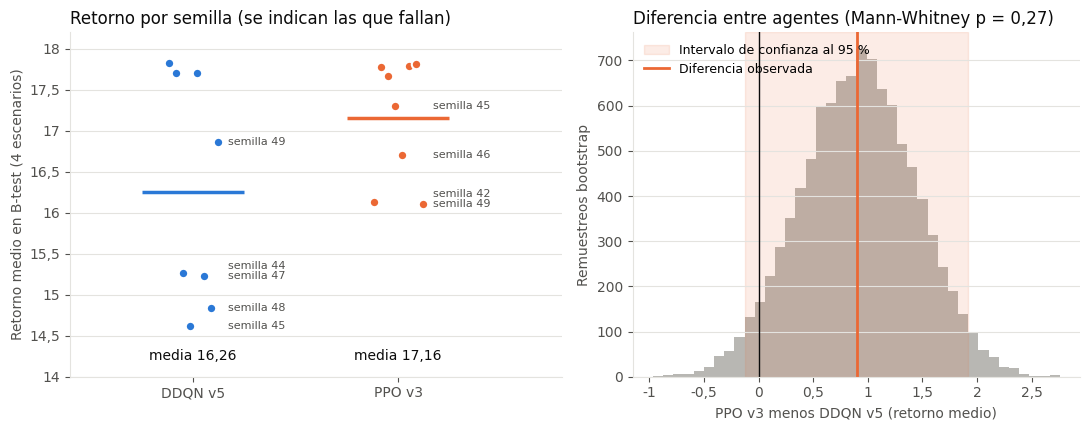

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
for j, agent in enumerate(['DDQN v5', 'PPO v3']):
    d = per_seed[per_seed.agente.eq(agent)]
    ax.scatter(np.full(len(d), j) + np.linspace(-.12, .12, len(d)), d.retorno, s=46,
               color=COLOR[agent], edgecolor='white', linewidth=1.5, zorder=3)
    last = None
    for _, r in d[d.falla.eq('sí')].sort_values('retorno').iterrows():
        y = r.retorno if last is None or r.retorno - last > .12 else last + .12
        ax.annotate(f'semilla {r.semilla}', (j + .17, y), fontsize=8, color=MUTED, va='center')
        last = y
    ax.hlines(d.retorno.mean(), j - .25, j + .25, color=COLOR[agent], lw=2.5)
    ax.text(j, 14.2, f'media {d.retorno.mean():.2f}'.replace('.', ','), ha='center', color=INK)
ax.set_xticks([0, 1], ['DDQN v5', 'PPO v3'])
ax.set(xlim=(-.6, 1.8), ylim=(14, 18.2), ylabel='Retorno medio en B-test (4 escenarios)')
ax.set_title('Retorno por semilla (se indican las que fallan)')

ax = axes[1]
ax.hist(boot, bins=40, color='#b8b7b3')
ax.axvline(0, color=INK, lw=1)
ax.axvspan(low, high, color=COLOR['PPO v3'], alpha=.12, label='Intervalo de confianza al 95 %')
ax.axvline(ppo.mean() - ddqn.mean(), color=COLOR['PPO v3'], lw=2, label='Diferencia observada')
ax.set(xlabel='PPO v3 menos DDQN v5 (retorno medio)', ylabel='Remuestreos bootstrap')
ax.set_title(f'Diferencia entre agentes (Mann-Whitney p = {p_value:.2f})'.replace('.', ','))
ax.legend(frameon=False, loc='upper left', fontsize=9)
plt.tight_layout()
save(fig, '03_analisis_de_grupo')

**Lectura.**

- PPO v3 tiene mayor media y la mitad de dispersión entre semillas, pero el intervalo de
  confianza incluye el 0 y p > 0,05. **Con 8 semillas no se puede afirmar que un agente
  supere al otro.**
- El **acuerdo** mide cuánto cambia la política entre checkpoints seguidos (1 = no
  cambia). PPO v3 es casi constante (en torno a 0,97) y DDQN cambia mucho (en torno a
  0,24). Por eso el checkpoint que elige DDQN depende más de la suerte.

## 6. Tipo de error: qué acciones elige cada agente

Total de acciones en B-test por semilla, sumando los cuatro escenarios (108 decisiones).
A3 y A4 son reentrenamientos.

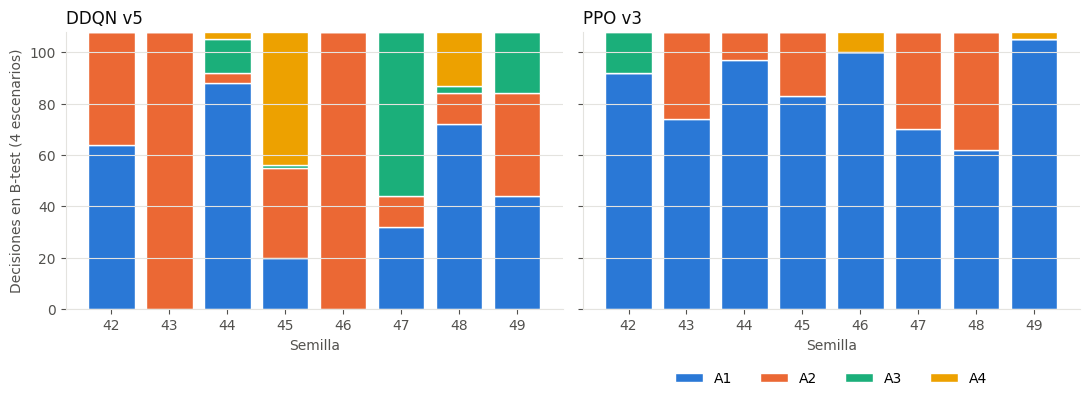

reentrenamientos en stable y concept (deberían ser 0),DDQN v5,PPO v3
semilla,,
42,0,0
43,0,0
44,5,0
45,23,0
46,0,0
47,23,0
48,18,0
49,17,0


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, agent in zip(axes, ['DDQN v5', 'PPO v3']):
    counts = seeds[seeds.agente.eq(agent)].groupby('semilla')[ACTIONS].sum()
    bottom = np.zeros(len(counts))
    for a in ACTIONS:
        ax.bar(counts.index.astype(str), counts[a], bottom=bottom, color=ACTION_COLOR[a],
               edgecolor='white', linewidth=1, label=a)
        bottom += counts[a].to_numpy()
    ax.set(title=agent, xlabel='Semilla')
axes[0].set_ylabel('Decisiones en B-test (4 escenarios)')
axes[1].legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(.5, -.18))
plt.tight_layout()
save(fig, '04_acciones_por_semilla')

retrain = seeds.assign(reentrena=seeds.A3 + seeds.A4)
retrain[retrain.escenario.isin(['stable', 'concept'])].pivot_table(
    index='semilla', columns='agente', values='reentrena', aggfunc='sum').rename_axis(
    columns='reentrenamientos en stable y concept (deberían ser 0)')

**Los dos agentes fallan de forma distinta.**

- **PPO v3 falla por prudencia.** Nunca reentrena en stable ni en concept. Cuando falla,
  es en covariate y combined, porque conserva el modelo (A1) en lugar de usar A2.
- **DDQN v5 falla por exceso.** En sus semillas malas reentrena también en stable y
  concept, donde no hay nada que corregir y solo pierde AUC y tiempo.

En un sistema clínico, un fallo prudente suele ser preferible a uno que modifica el
modelo sin necesidad.

## 7. Curvas de validación durante el entrenamiento

Retorno en B-validation cada 10 episodios. Cada línea es una semilla; el punto marca el
checkpoint elegido.

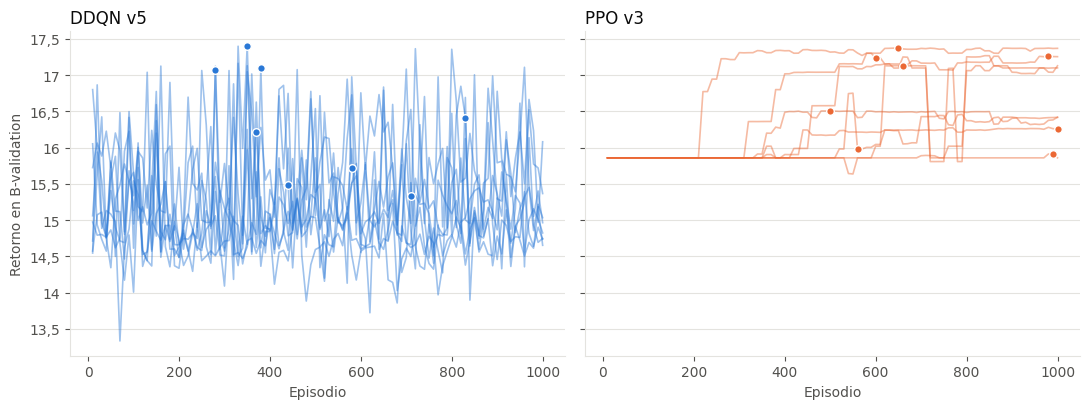

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, agent in zip(axes, ['DDQN v5', 'PPO v3']):
    for _, seed, path, _ in [r for r in RUNS if r[0] == agent]:
        h = pd.read_csv(K / path / 'training_history.csv').dropna(subset=['validation_return'])
        sel = pd.read_csv(K / path / 'checkpoint_selection.csv').iloc[-1]
        ax.plot(h.episode, h.validation_return, color=COLOR[agent], alpha=.45, lw=1.2)
        ax.scatter(sel.selected_episode, sel.selected_validation_return, s=30,
                   color=COLOR[agent], edgecolor='white', zorder=3)
    ax.set(title=agent, xlabel='Episodio')
axes[0].set_ylabel('Retorno en B-validation')
plt.tight_layout()
save(fig, '05_curvas_de_validacion')

DDQN oscila mucho durante todo el entrenamiento. Por eso el checkpoint elegido puede caer
en un momento bueno o malo según la semilla. PPO v3 sube por escalones y se mantiene, lo
que coincide con su acuerdo cercano a 1.

## 8. Mejor intento de PPO: curva de recompensa

Se elige el mejor intento de PPO (entre v1, v2 y v3 con todas sus semillas) por su retorno
medio en B-test, y se muestra su recompensa durante el entrenamiento.

retorno medio en B-test
agente semilla                         
PPO v3 48                         17,81
       47                         17,78
       43                         17,78
       44                         17,66
       45                         17,31

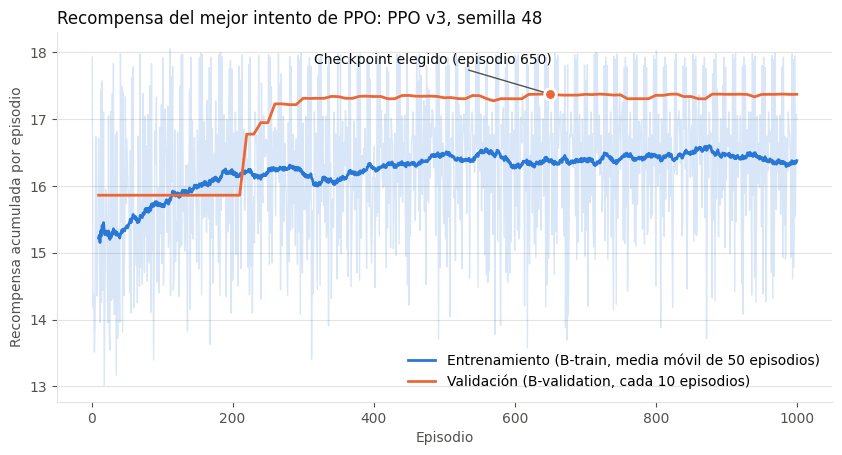

In [12]:
ppo_runs = (results[results.agente.str.startswith('PPO')]
            .groupby(['agente', 'semilla']).retorno.mean().sort_values(ascending=False))
display(ppo_runs.head(5).to_frame('retorno medio en B-test'))
best_agent, best_seed = ppo_runs.index[0]
best_path = next(K / p for a, s, p, _ in RUNS if (a, s) == (best_agent, best_seed))
h = pd.read_csv(best_path / 'training_history.csv')
val = h.dropna(subset=['validation_return'])
sel = pd.read_csv(best_path / 'checkpoint_selection.csv').iloc[-1]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(h.episode, h.train_return, color=COLOR['DDQN v5'], alpha=.18, lw=1)
ax.plot(h.episode, h.train_return.rolling(50, min_periods=10).mean(), color=COLOR['DDQN v5'], lw=2,
        label='Entrenamiento (B-train, media móvil de 50 episodios)')
ax.plot(val.episode, val.validation_return, color=COLOR['PPO v3'], lw=2,
        label='Validación (B-validation, cada 10 episodios)')
ax.scatter([sel.selected_episode], [sel.selected_validation_return], s=70, color=COLOR['PPO v3'],
           edgecolor='white', linewidth=2, zorder=5)
ax.annotate(f'Checkpoint elegido (episodio {int(sel.selected_episode)})',
            (sel.selected_episode, sel.selected_validation_return), xytext=(-170, 22),
            textcoords='offset points', color=INK, arrowprops=dict(arrowstyle='-', color=MUTED))
ax.set(xlabel='Episodio', ylabel='Recompensa acumulada por episodio')
ax.set_title(f'Recompensa del mejor intento de PPO: {best_agent}, semilla {best_seed}')
ax.legend(frameon=False, loc='lower right')
save(fig, '06_recompensa_mejor_ppo')

La recompensa de entrenamiento sube de forma continua y la de validación se estabiliza
hacia la mitad del entrenamiento: el agente aprende y no se desestabiliza después.

## 9. Conclusiones

1. **Rendimiento:** con 8 semillas, DDQN v5 y PPO v3 no se distinguen estadísticamente
   (16,26 frente a 17,16; p = 0,27). Las mejores semillas de ambos igualan a la mejor
   acción fija.
2. **Estabilidad:** PPO v3 es más predecible: menor dispersión entre semillas y una
   política casi constante entre checkpoints.
3. **Tipo de error:** PPO v3 nunca reentrena sin necesidad; DDQN sí lo hace en sus
   semillas malas.
4. **Limitación común:** ninguno descubre A2 de forma fiable en covariate y combined
   (PPO falla en 4 de 8 semillas y DDQN en 5 de 8).

**Limitaciones del análisis.**

- Las semillas 45 a 49 se ejecutaron en CPU y las 42 a 44 en GPU, por los límites de
  Kaggle. DDQN falla tanto en GPU (44) como en CPU (45, 47 y 48), así que no parece un
  efecto de la máquina.
- Se evalúa con un solo replay de B-test (la semilla 42 del entorno).
- PPO v3 se ajustó (de v1 a v3) mirando la semilla 42 y la validación, nunca B-test.
  DDQN v5 no tuvo esa iteración.

## 10. Preguntas para la profesora

**Decisión principal**

1. ¿Qué agente debe ser el principal de la tesis: DDQN (resultado original), PPO v3 (más
   estable y con un rendimiento parecido) o los dos presentados como comparación?
2. ¿Qué criterio debe pesar más al elegir: el retorno medio o la fiabilidad (rendir
   igual con cualquier semilla y no reentrenar sin necesidad)?

**Rigor del experimento**

3. ¿Bastan 8 semillas por agente, o conviene ampliar a 10 o más para la versión final?
   ¿Son adecuadas la prueba de Mann-Whitney y el intervalo bootstrap?
4. PPO se ajustó en tres versiones y DDQN no. ¿Hay que darle a DDQN una mejora
   equivalente (por ejemplo, en la exploración) para que la comparación sea justa?
5. Las semillas 42 a 44 se ejecutaron en GPU y las 45 a 49 en CPU. ¿Es aceptable o hay
   que repetirlas todas en la misma máquina?
6. ¿Basta con evaluar en un solo replay de B-test, o conviene añadir otros replays
   (otras semillas del entorno)?

**Problema de fondo**

7. Ninguno de los dos descubre A2 de forma fiable en covariate y combined. ¿Se prueba
   una observación más rica (por ejemplo, el día del episodio o los días desde el último
   reentrenamiento), o se deja como trabajo futuro?

**Tesis**

8. ¿Esta comparación va como sección propia del capítulo de resultados o como anexo?
9. ¿Se fusiona la rama `feature/ppo-experiments` con `main` una vez decidido el agente?